# Day 4 — PCA, Feature Engineering, Imbalanced Data, Leakage & Pipelines
**System 7 · Week 3 · Commit: `day-18-pca-pipelines`**

**Module B:** PCA, feature selection and engineering, imbalanced datasets, data leakage, scikit-learn pipelines.

**Practice questions solved today:** Q11, Q12, Q13 · **Module task:** customer segmentation · **Learning topics:** Data leakage, Curse of dimensionality

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings
from sklearn.datasets import load_wine, make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.cluster import KMeans
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
R = {}

## Q11 (Medium) — Imbalanced data: `class_weight` and recall before vs after
Imagine fraud detection where only **3 %** of transactions are fraud. A model can reach ~97 % accuracy by predicting "not fraud" every time, so we judge it by **recall on the minority class**.
`class_weight="balanced"` makes mistakes on the rare class cost more (weights are inversely proportional to class frequency), so the model stops ignoring it.

Class counts (train): {np.int64(0): np.int64(7242), np.int64(1): np.int64(258)} | fraud share: 0.034


                                                accuracy  precision  recall  \
Before (no class_weight) — LogReg                  0.970      0.875   0.163   
After (class_weight='balanced') — LogReg           0.773      0.102   0.721   
Before (no class_weight) — RandomForest            0.974      0.923   0.279   
After (class_weight='balanced') — RandomForest     0.978      0.897   0.407   

                                                   f1  
Before (no class_weight) — LogReg               0.275  
After (class_weight='balanced') — LogReg        0.179  
Before (no class_weight) — RandomForest         0.429  
After (class_weight='balanced') — RandomForest  0.560  


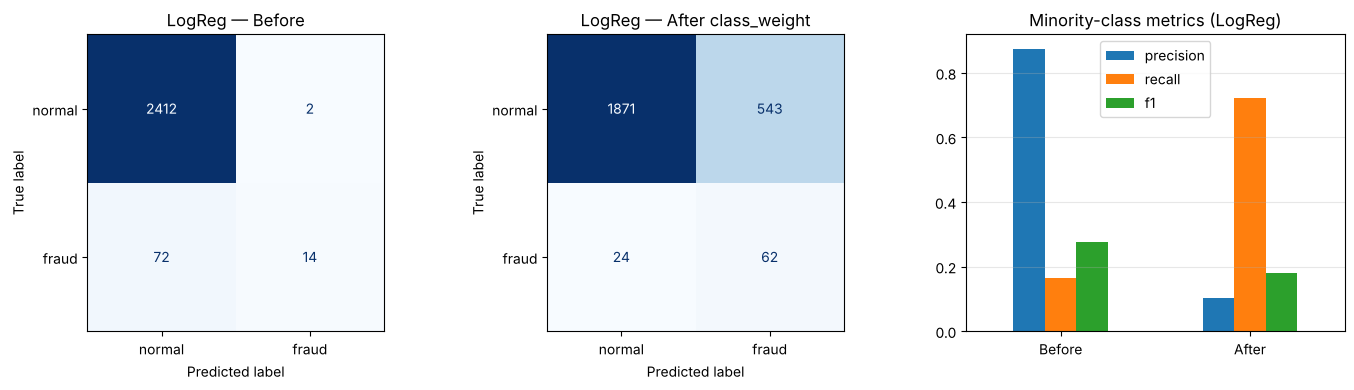

In [2]:
Xi, yi = make_classification(n_samples=10000, n_features=12, n_informative=6, n_redundant=2, weights=[0.97, 0.03], flip_y=0.01, class_sep=.9, random_state=RANDOM_STATE)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=.25, stratify=yi, random_state=RANDOM_STATE)
print("Class counts (train):", dict(zip(*np.unique(yi_tr, return_counts=True))), "| fraud share:", round(yi_tr.mean(), 3))

def report(model):
    p = model.predict(Xi_te)
    return dict(accuracy=accuracy_score(yi_te, p), precision=precision_score(yi_te, p, zero_division=0), recall=recall_score(yi_te, p), f1=f1_score(yi_te, p))

out = {}
for name, cw in [("Before (no class_weight)", None), ("After (class_weight='balanced')", "balanced")]:
    out[name + " — LogReg"] = report(make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, max_iter=1000)).fit(Xi_tr, yi_tr))
for name, cw in [("Before (no class_weight)", None), ("After (class_weight='balanced')", "balanced")]:
    out[name + " — RandomForest"] = report(RandomForestClassifier(200, class_weight=cw, random_state=RANDOM_STATE, n_jobs=-1).fit(Xi_tr, yi_tr))
tbl = pd.DataFrame(out).T.round(3); print(tbl)
R["q11"] = {"logreg_recall_before": round(tbl.iloc[0].recall, 3), "logreg_recall_after": round(tbl.iloc[1].recall, 3),
            "logreg_precision_before": round(tbl.iloc[0].precision, 3), "logreg_precision_after": round(tbl.iloc[1].precision, 3),
            "rf_recall_before": round(tbl.iloc[2].recall, 3), "rf_recall_after": round(tbl.iloc[3].recall, 3)}

lr_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_tr, yi_tr)
lr_a = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(Xi_tr, yi_tr)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (t, m) in zip(ax[:2], [("Before", lr_b), ("After class_weight", lr_a)]):
    ConfusionMatrixDisplay.from_estimator(m, Xi_te, yi_te, display_labels=["normal", "fraud"], cmap="Blues", ax=a, colorbar=False); a.set_title(f"LogReg — {t}")
tbl.loc[[tbl.index[0], tbl.index[1]], ["precision", "recall", "f1"]].set_axis(["Before", "After"]).plot.bar(ax=ax[2], rot=0); ax[2].set_title("Minority-class metrics (LogReg)"); ax[2].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

**Result:** with `class_weight="balanced"` recall on the rare class jumps, at the price of lower precision (more false alarms). This trade-off is deliberate: for fraud/medical problems a missed positive costs more than a false alarm. Other options (not needed here) include over-sampling (SMOTE), under-sampling, and moving the decision threshold.

## Q12 (Hard) — PCA to 2 components: plot the clusters and report explained variance
**PCA** rotates the data onto new, uncorrelated axes (*principal components*) ordered by how much variance they capture. Keeping the first few compresses the data with little loss. PCA is sensitive to scale, so we standardise first.
Dataset: **Wine** (178 samples, 13 chemical features, 3 cultivars).

Explained variance  PC1: 36.20%  PC2: 19.21%  | total (2 components): 55.41%


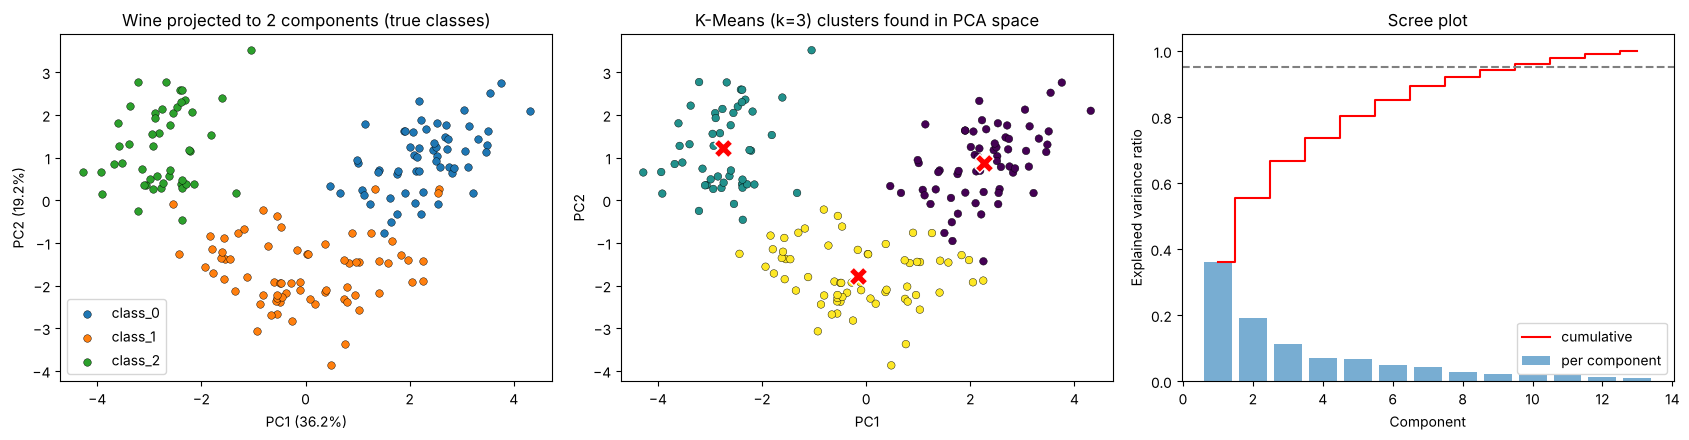

Components needed for 95% variance: 10 of 13
K-Means vs true cultivar (ARI): 0.895


,PC1,PC2
flavanoids,0.42,-0.00
total_phenols,0.39,0.07
od280/od315_of_diluted_wines,0.38,-0.16
proanthocyanins,0.31,0.04
nonflavanoid_phenols,-0.30,0.03
hue,0.30,-0.28


In [3]:
wine = load_wine(as_frame=True); Xw, yw = wine.data, wine.target
Xw_s = StandardScaler().fit_transform(Xw)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE); Z2 = pca2.fit_transform(Xw_s)
ev = pca2.explained_variance_ratio_
print(f"Explained variance  PC1: {ev[0]:.2%}  PC2: {ev[1]:.2%}  | total (2 components): {ev.sum():.2%}")
R["q12"] = {"pc1": round(float(ev[0]), 4), "pc2": round(float(ev[1]), 4), "total": round(float(ev.sum()), 4)}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for c, n in enumerate(wine.target_names): ax[0].scatter(*Z2[yw == c].T, label=n, s=30, edgecolor="k", lw=.3)
ax[0].set(xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})", title="Wine projected to 2 components (true classes)"); ax[0].legend()

km = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit(Z2)
ax[1].scatter(*Z2.T, c=km.labels_, cmap="viridis", s=30, edgecolor="k", lw=.3); ax[1].scatter(*km.cluster_centers_.T, c="r", marker="X", s=180, edgecolor="w")
ax[1].set(xlabel="PC1", ylabel="PC2", title="K-Means (k=3) clusters found in PCA space")

full = PCA().fit(Xw_s); cum = np.cumsum(full.explained_variance_ratio_)
ax[2].bar(range(1, 14), full.explained_variance_ratio_, alpha=.6, label="per component"); ax[2].step(range(1, 14), cum, where="mid", color="r", label="cumulative"); ax[2].axhline(.95, ls="--", color="gray")
ax[2].set(xlabel="Component", ylabel="Explained variance ratio", title="Scree plot"); ax[2].legend()
plt.tight_layout(); plt.show()
n95 = int(np.argmax(cum >= .95)) + 1; print(f"Components needed for 95% variance: {n95} of 13")
R["q12"]["n95"] = n95
from sklearn.metrics import adjusted_rand_score
R["q12"]["kmeans_ari"] = round(adjusted_rand_score(yw, km.labels_), 3); print("K-Means vs true cultivar (ARI):", R["q12"]["kmeans_ari"])
loadings = pd.DataFrame(pca2.components_.T, index=Xw.columns, columns=["PC1", "PC2"]).round(2); loadings.reindex(loadings.PC1.abs().sort_values(ascending=False).index).head(6)

Two components keep a bit over half of the total variance (exact figures printed above) and the three wine classes are already clearly separated, even though PCA never saw the labels; K-Means on just these 2 axes recovers the real cultivars with a high agreement score (ARI). The scree plot shows how many components would be needed to keep ~95 % of the variance — compressing 13 features to 2 is a trade of some information for simplicity and a plot you can see.

## Q13 (Hard) — Pipeline (scaler → PCA → classifier) and a data-leakage demonstration
A `Pipeline` chains preprocessing and the model into **one estimator**. In cross-validation, every step is re-fitted on the training folds only, so nothing about the validation fold leaks in.

In [4]:
pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=5, random_state=RANDOM_STATE)), ("clf", LogisticRegression(max_iter=1000))])
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=.25, stratify=yw, random_state=RANDOM_STATE)
pipe.fit(Xw_tr, yw_tr)
print(f"Pipeline test accuracy: {pipe.score(Xw_te, yw_te):.4f} | explained variance of 5 PCs: {pipe.named_steps['pca'].explained_variance_ratio_.sum():.2%}")
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("Pipeline 5-fold CV:", cross_val_score(pipe, Xw, yw, cv=cv).round(3), "mean =", cross_val_score(pipe, Xw, yw, cv=cv).mean().round(4))

Pipeline test accuracy: 0.9778 | explained variance of 5 PCs: 80.16%
Pipeline 5-fold CV: [0.972 0.944 0.972 1.    1.   ] mean = 0.9778


### Leakage demo A — scaling *before* the split (what the question asks)
**Wrong:** fit the scaler on the *whole* dataset, then split → the test rows influenced the mean/std used on the training rows.
**Right:** split first, fit the scaler on train only (the pipeline does this automatically).
To measure the difference fairly I repeat the experiment over **200 random splits**.

Scale BEFORE split (leaky): 0.9820
Pipeline (correct)        : 0.9747
Difference: +0.0073


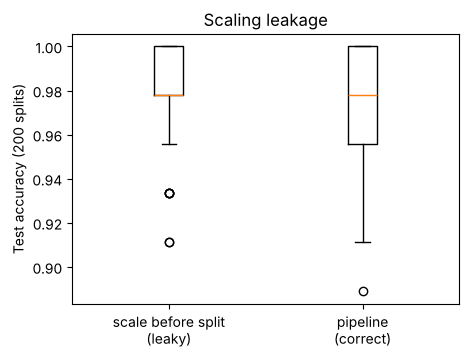

In [5]:
wrong_scores, right_scores = [], []
for seed in range(200):
    # WRONG: scale everything first, then split
    Xs_all = StandardScaler().fit_transform(Xw)
    a_tr, a_te, b_tr, b_te = train_test_split(Xs_all, yw, test_size=.25, stratify=yw, random_state=seed)
    wrong_scores.append(LogisticRegression(max_iter=1000).fit(a_tr, b_tr).score(a_te, b_te))
    # RIGHT: split first, scaler is fitted inside the pipeline on train only
    a_tr, a_te, b_tr, b_te = train_test_split(Xw, yw, test_size=.25, stratify=yw, random_state=seed)
    right_scores.append(pipe.fit(a_tr, b_tr).score(a_te, b_te))
w, r = np.mean(wrong_scores), np.mean(right_scores)
print(f"Scale BEFORE split (leaky): {w:.4f}\nPipeline (correct)        : {r:.4f}\nDifference: {w - r:+.4f}")
R["q13"] = {"leaky": round(w, 4), "correct": round(r, 4)}
plt.figure(figsize=(5, 3.5)); plt.boxplot([wrong_scores, right_scores]); plt.xticks([1, 2], ["scale before split\n(leaky)", "pipeline\n(correct)"]); plt.ylabel("Test accuracy (200 splits)"); plt.title("Scaling leakage"); plt.show()

**Honest reading:** leakage from *scaling* is usually **tiny** because a mean and standard deviation reveal very little about individual test labels — the gap above is small and could go either way. That is exactly why leakage is dangerous: it is silent. Leakage becomes dramatic when the leaking step *uses the labels*, such as feature selection. Demo B shows this on pure noise.

### Leakage demo B — feature selection before cross-validation (dramatic)
Data: **100 random samples, 2,000 random features, random labels.** There is *nothing* to learn, so honest accuracy must be ≈ 50 %.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
Xn = rng.normal(size=(100, 2000)); yn = rng.integers(0, 2, 100)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

# WRONG: pick the 20 "best" features using ALL labels, then cross-validate
Xsel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
leaky = cross_val_score(LogisticRegression(max_iter=1000), Xsel, yn, cv=cv).mean()
# RIGHT: selection inside the pipeline, re-done on each training fold
ok_pipe = Pipeline([("select", SelectKBest(f_classif, k=20)), ("clf", LogisticRegression(max_iter=1000))])
honest = cross_val_score(ok_pipe, Xn, yn, cv=cv).mean()
print(f"Leaky CV accuracy on pure noise : {leaky:.3f}   <- looks like a great model!\nPipeline CV accuracy on noise   : {honest:.3f}   <- honest answer (≈ coin flip)")
R["q13"].update({"noise_leaky": round(leaky, 3), "noise_honest": round(honest, 3)})

Leaky CV accuracy on pure noise : 0.860   <- looks like a great model!
Pipeline CV accuracy on noise   : 0.580   <- honest answer (≈ coin flip)


## Feature selection & engineering (applied to the student data)
* **Feature engineering** = creating better inputs from existing ones (ratios, interactions, bins, date parts).
* **Feature selection** = dropping inputs that add noise or cost (filter methods like `SelectKBest`, model-based importances).

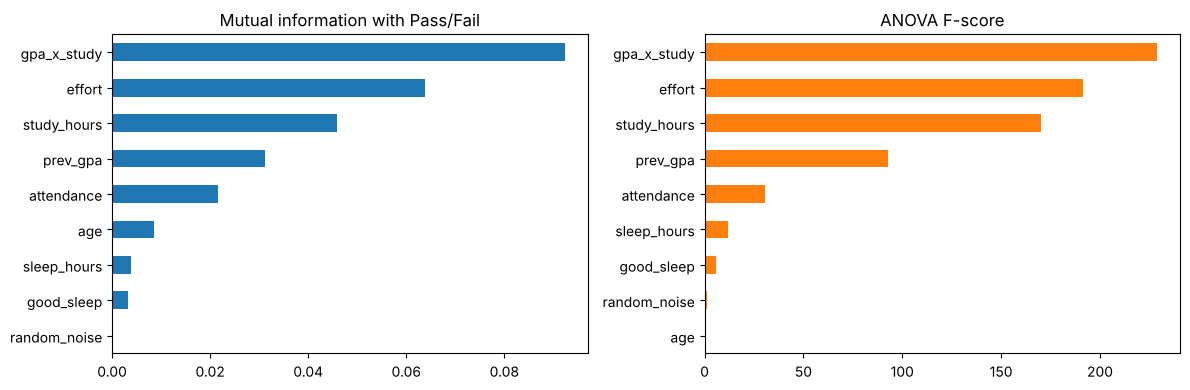

Original 5 features: 0.7992 | + engineered features: 0.8025 | top-5 by F-score ['gpa_x_study', 'effort', 'study_hours', 'prev_gpa', 'attendance']: 0.7942
The useless noise column ranks #9 of 9 by mutual information and #8 of 9 by F-score -> safe to drop.


In [7]:
students = pd.read_csv("students.csv") if __import__("os").path.exists("students.csv") else None
if students is None:
    rng = np.random.default_rng(42); n = 1200
    students = pd.DataFrame({"study_hours": rng.normal(3, 1.5, n).clip(0, 10).round(1), "attendance": rng.normal(80, 12, n).clip(30, 100).round(),
                             "prev_gpa": rng.normal(2.9, .55, n).clip(1, 4).round(2), "sleep_hours": rng.normal(6.8, 1.2, n).clip(3, 10).round(1), "age": rng.integers(18, 26, n)})
    sc = 5 + 3.5*students.study_hours + .2*students.attendance + 7*students.prev_gpa + .8*students.sleep_hours + rng.normal(0, 7, n)
    students["result"] = np.where(sc >= 55, "Pass", "Fail"); students.to_csv("students.csv", index=False)
fe = students[["study_hours", "attendance", "prev_gpa", "sleep_hours", "age"]].copy(); target = (students.result == "Pass").astype(int)
fe["effort"] = fe.study_hours * fe.attendance / 100          # engineered: study time weighted by attendance
fe["gpa_x_study"] = fe.prev_gpa * fe.study_hours             # engineered: interaction
fe["good_sleep"] = fe.sleep_hours.between(7, 9).astype(int)  # engineered: binary flag
fe["random_noise"] = np.random.default_rng(0).normal(size=len(fe))   # a useless feature on purpose

mi = pd.Series(mutual_info_classif(fe, target, random_state=RANDOM_STATE), index=fe.columns).sort_values()
fs = pd.Series(SelectKBest(f_classif, k="all").fit(fe, target).scores_, index=fe.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); mi.plot.barh(ax=ax[0], title="Mutual information with Pass/Fail"); fs.plot.barh(ax=ax[1], color="tab:orange", title="ANOVA F-score"); plt.tight_layout(); plt.show()

cvs = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE); base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
orig = ["study_hours", "attendance", "prev_gpa", "sleep_hours", "age"]
s1 = cross_val_score(base, fe[orig], target, cv=cvs).mean(); s2 = cross_val_score(base, fe.drop(columns="random_noise"), target, cv=cvs).mean()
top = list(fs.sort_values(ascending=False).index[:5]); s3 = cross_val_score(base, fe[top], target, cv=cvs).mean()
print(f"Original 5 features: {s1:.4f} | + engineered features: {s2:.4f} | top-5 by F-score {top}: {s3:.4f}")
print(f"The useless noise column ranks #{int(list(mi.index[::-1]).index('random_noise'))+1} of {len(mi)} by mutual information and #{int(list(fs.index[::-1]).index('random_noise'))+1} of {len(fs)} by F-score -> safe to drop.")
R["fe"] = {"orig": round(s1, 4), "engineered": round(s2, 4), "top5": round(s3, 4)}

---
# Module B practical task — Customer segmentation
**Goal:** group customers into actionable segments for marketing. **Plan:** scale → (PCA for visualisation) → K-Means, choose *k* with silhouette, profile each segment, recommend actions. Everything lives in one `Pipeline`.

In [8]:
import os
if os.path.exists("customers.csv"): cust = pd.read_csv("customers.csv")
else:   # same generator as Day 3
    rng = np.random.default_rng(RANDOM_STATE); groups = [(110, 25, 30, 75), (100, 45, 85, 20), (100, 30, 90, 85), (100, 55, 35, 25), (90, 35, 55, 50)]
    cust = pd.concat([pd.DataFrame({"age": rng.normal(a, 4, n), "annual_income_k": rng.normal(i, 7, n), "spending_score": rng.normal(s, 8, n)}) for n, a, i, s in groups], ignore_index=True)
    cust = cust.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True); cust["age"] = cust.age.clip(18, 70).round(); cust.insert(0, "customer_id", range(1, len(cust)+1)); cust.to_csv("customers.csv", index=False)
feat = ["age", "annual_income_k", "spending_score"]
print(cust.shape); cust[feat].describe().round(1).T[["mean", "std", "min", "max"]]

(500, 4)


,mean,std,min,max
age,37.6,11.7,18.0,64.0
annual_income_k,58.8,26.0,15.1,104.3
spending_score,51.1,27.9,1.0,100.0


{2: 0.459, 3: 0.502, 4: 0.576, 5: 0.619, 6: 0.544, 7: 0.471, 8: 0.41} -> best k = 5


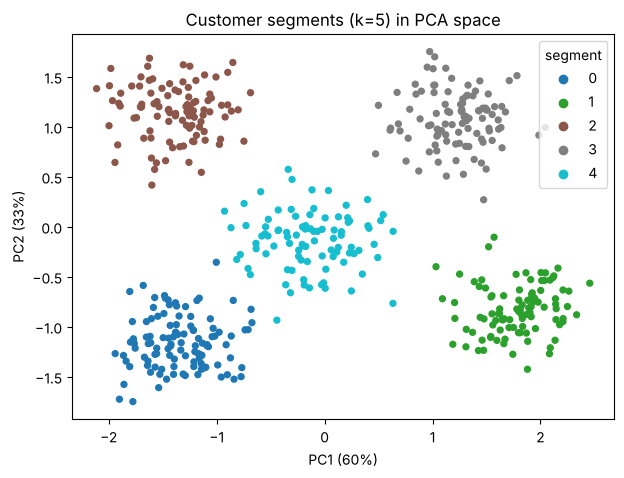

,customers,avg_age,avg_income_k,avg_spending
segment,,,,
0,110,24.8,29.9,75.3
1,99,55.2,35.7,24.0
2,100,29.4,90.2,84.6
3,100,44.9,85.3,18.6
4,91,34.8,55.1,50.1


In [9]:
ks = range(2, 9); scores = {}
for k in ks:
    p = Pipeline([("scale", StandardScaler()), ("km", KMeans(k, n_init=10, random_state=RANDOM_STATE))]).fit(cust[feat])
    scores[k] = silhouette_score(p.named_steps["scale"].transform(cust[feat]), p.named_steps["km"].labels_)
best_k = max(scores, key=scores.get); print({k: round(v, 3) for k, v in scores.items()}, "-> best k =", best_k)

seg_pipe = Pipeline([("scale", StandardScaler()), ("km", KMeans(best_k, n_init=10, random_state=RANDOM_STATE))]).fit(cust[feat])
cust["segment"] = seg_pipe.named_steps["km"].labels_
Zc = PCA(2, random_state=RANDOM_STATE).fit(seg_pipe.named_steps["scale"].transform(cust[feat]))
Zp = Zc.transform(seg_pipe.named_steps["scale"].transform(cust[feat]))
plt.figure(figsize=(7, 5)); sc = plt.scatter(*Zp.T, c=cust.segment, cmap="tab10", s=18); plt.legend(*sc.legend_elements(), title="segment")
plt.xlabel(f"PC1 ({Zc.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({Zc.explained_variance_ratio_[1]:.0%})"); plt.title(f"Customer segments (k={best_k}) in PCA space"); plt.show()
profile = cust.groupby("segment").agg(customers=("customer_id", "count"), avg_age=("age", "mean"), avg_income_k=("annual_income_k", "mean"), avg_spending=("spending_score", "mean")).round(1)
profile

In [10]:
mu_i, sd_i = cust.annual_income_k.mean(), cust.annual_income_k.std(); mu_s, sd_s = cust.spending_score.mean(), cust.spending_score.std()
level = lambda v, mu, sd: "high" if v > mu + .5*sd else ("low" if v < mu - .5*sd else "mid")      # high / mid / low vs the overall average
def name_segment(r):
    inc, sp = level(r.avg_income_k, mu_i, sd_i), level(r.avg_spending, mu_s, sd_s)
    table = {("high", "high"): ("VIPs — high income, high spend", "Loyalty tier, early access to premium products"),
             ("high", "low"):  ("Careful affluent — high income, low spend", "Personalised offers and recommendations to unlock spend"),
             ("low", "high"):  ("Enthusiastic spenders — lower income, high spend", "Instalment plans, bundles, young-adult promotions"),
             ("low", "low"):   ("Budget-conscious — low income, low spend", "Value deals, low-cost email retention, avoid heavy discounts"),
             ("mid", "mid"):   ("Mainstream — average income, average spend", "Seasonal campaigns and cross-selling to move them up a tier")}
    return table.get((inc, sp), (f"Mixed — {inc} income, {sp} spend", "Review manually"))
names = profile.apply(name_segment, axis=1, result_type="expand"); names.columns = ["segment_name", "recommended_action"]
final = profile.join(names); pd.set_option("display.max_colwidth", 80); final
R["segmentation"] = {"k": int(best_k), "silhouette": round(scores[best_k], 3), "segments": final.reset_index().to_dict("records")}

**Business reading:** each segment has a different income/spending/age profile and therefore needs a different marketing action (table above). Segments are not "true" categories — they are a useful simplification, so check them with the business before acting.

## Learning topics
**Data leakage** — information from outside the training data (test rows, the target, or the future) sneaks into model building, producing scores that look great in the notebook and collapse in production. Typical causes: scaling/imputing/selecting features on the full dataset before splitting, duplicated rows across train and test, features that are really the label in disguise. **Cure:** split first, put every fitted step inside a `Pipeline`, and cross-validate the *whole pipeline* (Demo B shows the damage when this is ignored).

**Curse of dimensionality** — as the number of features grows, data becomes sparse: distances between points become nearly equal, models need exponentially more data, and overfitting becomes easy. PCA (compress correlated features) and feature selection (drop useless ones) fight this. A quick demonstration:

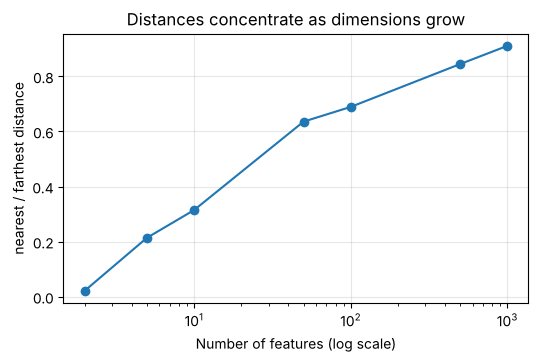

{2: np.float64(0.02), 5: np.float64(0.21), 10: np.float64(0.31), 50: np.float64(0.64), 100: np.float64(0.69), 500: np.float64(0.84), 1000: np.float64(0.91)} 
-> In high dimensions 'nearest' and 'farthest' neighbours are almost equally far, which hurts KNN, K-Means and SVM.


In [11]:
rng = np.random.default_rng(RANDOM_STATE); dims = [2, 5, 10, 50, 100, 500, 1000]; ratio = []
for d in dims:
    P = rng.uniform(size=(500, d)); dist = np.linalg.norm(P[1:] - P[0], axis=1)
    ratio.append(dist.min() / dist.max())
plt.figure(figsize=(6, 3.5)); plt.semilogx(dims, ratio, "o-"); plt.xlabel("Number of features (log scale)"); plt.ylabel("nearest / farthest distance"); plt.title("Distances concentrate as dimensions grow"); plt.grid(alpha=.3); plt.show()
print(dict(zip(dims, np.round(ratio, 2))), "\n-> In high dimensions 'nearest' and 'farthest' neighbours are almost equally far, which hurts KNN, K-Means and SVM.")
R["curse"] = dict(zip(map(str, dims), np.round(ratio, 3).tolist()))

### Summary of Day 4
| Topic | Key point |
|---|---|
| Imbalanced data | Judge by minority-class recall/precision; `class_weight` trades precision for recall |
| PCA | Standardise first; keep components that explain enough variance; unsupervised |
| Pipelines | One object, no leakage in cross-validation, easy to deploy |
| Leakage | Split first; anything fitted on data belongs inside the pipeline |
| Segmentation | Scale → cluster → profile → name segments → act |

In [12]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
